In [64]:
%pip install scikit-learn numpy pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


In [79]:
import pandas as pd
df = pd.read_csv(r"D:\FinTech\MasterClass-FinTech-01\session_1\2.california_cities\california_cities.csv")
df.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          482 non-null    int64  
 1   city                482 non-null    str    
 2   latd                482 non-null    float64
 3   longd               482 non-null    float64
 4   elevation_m         434 non-null    float64
 5   elevation_ft        470 non-null    float64
 6   population_total    482 non-null    int64  
 7   area_total_sq_mi    480 non-null    float64
 8   area_land_sq_mi     482 non-null    float64
 9   area_water_sq_mi    481 non-null    float64
 10  area_total_km2      477 non-null    float64
 11  area_land_km2       478 non-null    float64
 12  area_water_km2      478 non-null    float64
 13  area_water_percent  477 non-null    float64
dtypes: float64(11), int64(2), str(1)
memory usage: 52.8 KB


In [81]:
df.shape

(482, 14)

# handling missing data

Analysis:
As indicated by the dataframe information, there are some non-null values ​​in `area_water_km2`. Therefore, it is preferable to use `area_water_sq_mile`, which contains fewer null values. Additionally, by calculating the difference between `area_total_sq_mi` and `area_land_sq_mi`, we may be able to determine the correct values ​​for entries where `area_water_sq_mi` is currently null.

In [82]:
df.isna().sum()

Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m           48
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         5
area_land_km2          4
area_water_km2         4
area_water_percent     5
dtype: int64

In [83]:
SQMI_TO_KM = 2.58
df['area_water_km2'] = (df['area_water_km2'].fillna(df['area_total_km2'] - df['area_land_km2']))
print(df['area_water_km2'].isna().sum())
df['area_water_km2'] = (df['area_water_km2'].fillna(df['area_water_sq_mi']*SQMI_TO_KM))
print(df['area_water_km2'].isna().sum())
df['area_water_km2'] = (df['area_water_km2'].fillna((df['area_total_sq_mi']-df['area_land_sq_mi'])*SQMI_TO_KM))
print(df['area_water_km2'].isna().sum())

4
0
0


In [71]:
df.isna().sum()

Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m           48
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         5
area_land_km2          4
area_water_km2         0
area_water_percent     5
dtype: int64

In [84]:
df.columns

Index(['Unnamed: 0', 'city', 'latd', 'longd', 'elevation_m', 'elevation_ft',
       'population_total', 'area_total_sq_mi', 'area_land_sq_mi',
       'area_water_sq_mi', 'area_total_km2', 'area_land_km2', 'area_water_km2',
       'area_water_percent'],
      dtype='str')

# validating dataframe

Analysis:

As indicated by the DataFrame, there are several null values ​​and inconsistencies within the `area_water_km2` column. Consequently, to verify the accuracy of the data, one can utilize related columns such as `area_water_sq_mi`, `area_total_sq_mi`, and `area_land_sq_mi`. Since the water area (in square miles) can be derived by subtracting the land area from the total area (both in square miles), this relationship—provided the relevant values ​​are valid—can be used to estimate the water area and to validate or fill in missing data.

To this end, three validation criteria were applied to assess data consistency. The first criterion compares the `area_water_km2` value against the difference between `area_total_km2` and `area_land_km2`. The second criterion calculates the percentage of water area—based on the ratio of water area to total area—and compares it with the value recorded in `area_water_percent`. The third criterion employs the columns representing area in square miles; after performing the necessary calculations and converting the units to square kilometers, the results are compared against the value recorded in `area_water_km2` to ensure consistency.

In [85]:

import pandas as pd
import numpy as np


validation = df.copy()

validation["water_km2_calculated"] = (
    validation["area_total_km2"] - validation["area_land_km2"]
)
validation["water_km2_difference"] = (
    validation["area_water_km2"] - validation["water_km2_calculated"]
)

validation["km2_check"] = np.select(
    [
        validation["water_km2_difference"].abs() <= 0.01,
        validation["water_km2_difference"].isna(),
    ],
    ["Pass", "Cannot validate"],
    default="Review"
)

valid_total = validation["area_total_km2"].where(
    validation["area_total_km2"] > 0
)
validation["water_percent_calculated"] = (
    validation["area_water_km2"] / valid_total * 100
)
validation["water_percent_difference"] = (
    validation["area_water_percent"]
    - validation["water_percent_calculated"]
)

validation["percent_check"] = np.select(
    [
        validation["water_percent_difference"].abs() <= 0.1,
        validation["water_percent_difference"].isna(),
    ],
    ["Pass", "Cannot validate"],
    default="Review"
)

validation["water_sq_mi_calculated"] = (
    validation["area_total_sq_mi"] - validation["area_land_sq_mi"]
)
validation["water_km2_from_sq_mi"] = (
    validation["water_sq_mi_calculated"] * 2.589988110336
)
validation["sq_mi_crosscheck_difference"] = (
    validation["area_water_km2"] - validation["water_km2_from_sq_mi"]
)

validation["sq_mi_check"] = np.select(
    [
        validation["sq_mi_crosscheck_difference"].abs() <= 0.02,
        validation["sq_mi_crosscheck_difference"].isna(),
    ],
    ["Pass", "Cannot validate"],
    default="Review"
)

# 5. Summarize validation results
print("\n=== km² Validation ===")
print(validation["km2_check"].value_counts())

print("\n=== Percentage Validation ===")
print(validation["percent_check"].value_counts())

print("\n=== Square-Mile Cross-Check ===")
print(validation["sq_mi_check"].value_counts())



=== km² Validation ===
km2_check
Pass               474
Cannot validate      5
Review               3
Name: count, dtype: int64

=== Percentage Validation ===
percent_check
Pass               473
Cannot validate      7
Review               2
Name: count, dtype: int64

=== Square-Mile Cross-Check ===
sq_mi_check
Pass               472
Review               8
Cannot validate      2
Name: count, dtype: int64


In [86]:

review_km2 = set(validation.index[validation["km2_check"] == "Review"])
review_percent = set(validation.index[validation["percent_check"] == "Review"])
review_sq_mi = set(validation.index[validation["sq_mi_check"] == "Review"])


print("Review in km² check:", len(review_km2))
print("Review in percentage check:", len(review_percent))
print("Review in sq_mi check:", len(review_sq_mi))

print("\nReview in both km² and percentage:")
print(sorted(review_km2 & review_percent))

print("\nReview in both km² and sq_mi:")
print(sorted(review_km2 & review_sq_mi))

print("\nReview in both percentage and sq_mi:")
print(sorted(review_percent & review_sq_mi))

print("\nReview in all three methods:")
print(sorted(review_km2 & review_percent & review_sq_mi))

print("\nReview in at least one method:")
print(sorted(review_km2 | review_percent | review_sq_mi))


Review in km² check: 3
Review in percentage check: 2
Review in sq_mi check: 8

Review in both km² and percentage:
[142]

Review in both km² and sq_mi:
[142, 446, 466]

Review in both percentage and sq_mi:
[136, 142]

Review in all three methods:
[142]

Review in at least one method:
[136, 142, 143, 197, 239, 370, 446, 466]


We observe that data point 142 requires review according to all three criteria.

In [87]:

display(validation.loc[
    [142],
    ["area_total_sq_mi", "area_land_sq_mi", "area_water_sq_mi", "area_total_km2",'area_land_km2', 'area_water_km2',
       'area_water_percent']
])

,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
142,42.432,42.432,3.0,109.899,109.899,6.0,3.0


We observe that data point 142 requires review according to all three criteria.
Upon examining the corresponding row, we find that there are no negative or zero values. Since the data in this row cannot be recovered using the available information, it must be removed from the dataframe for any subsequent analyses.

In [88]:
validation.columns

Index(['Unnamed: 0', 'city', 'latd', 'longd', 'elevation_m', 'elevation_ft',
       'population_total', 'area_total_sq_mi', 'area_land_sq_mi',
       'area_water_sq_mi', 'area_total_km2', 'area_land_km2', 'area_water_km2',
       'area_water_percent', 'water_km2_calculated', 'water_km2_difference',
       'km2_check', 'water_percent_calculated', 'water_percent_difference',
       'percent_check', 'water_sq_mi_calculated', 'water_km2_from_sq_mi',
       'sq_mi_crosscheck_difference', 'sq_mi_check'],
      dtype='str')

In [94]:
display( validation.loc[
    [136, 143, 197, 239, 446, 466],
    ["area_total_sq_mi", "area_land_sq_mi", "area_water_sq_mi", "area_total_km2",'area_land_km2', 'area_water_km2',
       'area_water_percent','water_km2_calculated', 'water_km2_difference',
       'km2_check', 'water_percent_calculated', 'water_percent_difference',
       'percent_check', 'water_sq_mi_calculated', 'water_km2_from_sq_mi',
       'sq_mi_crosscheck_difference', 'sq_mi_check']
])

KeyError: '[136, 446, 466] not in index'

Based on the results, we calculate the water percentage for rows 143 and 197, retain the existing values for row 239, and remove rows 136, 142, 446, and 466 due to insufficient or inconsistent data.

In [91]:

validation_backup = validation.copy()
rows_to_fix = [143, 197]

validation.loc[rows_to_fix, "area_water_percent"] = (
    validation.loc[rows_to_fix, "area_water_km2"]
    / validation.loc[rows_to_fix, "area_total_km2"]
    * 100
)
rows_to_remove = [136, 142, 446, 466]

validation = validation.drop(index=rows_to_remove)


display(
    validation.loc[
        [143, 197, 239],
        [
            "city",
            "area_water_km2",
            "area_water_percent"
        ]
    ]
)

,city,area_water_km2,area_water_percent
143,FortBragg,0.1,1.388889
197,JurupaValley,0.6,0.532387
239,LosAngeles,88.0,6.700000


In [95]:
display( validation.loc[
    [143, 197, 239],
    ["area_total_sq_mi", "area_land_sq_mi", "area_water_sq_mi", "area_total_km2",'area_land_km2', 'area_water_km2',
       'area_water_percent','water_km2_calculated', 'water_km2_difference',
       'km2_check', 'water_percent_calculated', 'water_percent_difference',
       'percent_check', 'water_sq_mi_calculated', 'water_km2_from_sq_mi',
       'sq_mi_crosscheck_difference', 'sq_mi_check']
])

,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent,water_km2_calculated,water_km2_difference,km2_check,water_percent_calculated,water_percent_difference,percent_check,water_sq_mi_calculated,water_km2_from_sq_mi,sq_mi_crosscheck_difference,sq_mi_check
143,2.8,2.7,NaN,7.2,7.1,0.1,1.388889,0.1,-5.273559e-16,Pass,1.388889,NaN,Cannot validate,0.1,0.258999,-0.158999,Review
197,43.5,43.3,0.2,112.7,112.1,0.6,0.532387,0.6,-8.548717e-15,Pass,0.532387,NaN,Cannot validate,0.2,0.517998,0.082002,Review
239,503.0,469.0,34.0,1302.0,1214.0,88.0,6.700000,88.0,0.000000e+00,Pass,6.758833,-0.058833,Pass,34.0,88.059596,-0.059596,Review


In [96]:
df = validation
df.isna().sum()

Unnamed: 0                      0
city                            0
latd                            0
longd                           0
elevation_m                    48
elevation_ft                   12
population_total                0
area_total_sq_mi                2
area_land_sq_mi                 0
area_water_sq_mi                1
area_total_km2                  5
area_land_km2                   4
area_water_km2                  0
area_water_percent              3
water_km2_calculated            5
water_km2_difference            5
km2_check                       0
water_percent_calculated        5
water_percent_difference        7
percent_check                   0
water_sq_mi_calculated          2
water_km2_from_sq_mi            2
sq_mi_crosscheck_difference     2
sq_mi_check                     0
dtype: int64

In [105]:
result = validation.sort_values(
    by="area_water_km2",
    ascending=False
).head(6)

print(result[["city", "area_water_km2"]])

             city  area_water_km2
370  SanFrancisco        477.3516
367      SanDiego        122.2700
239    LosAngeles         88.0000
285  NewportBeach         75.5570
93       Coronado         64.0620
104     DanaPoint         59.5360


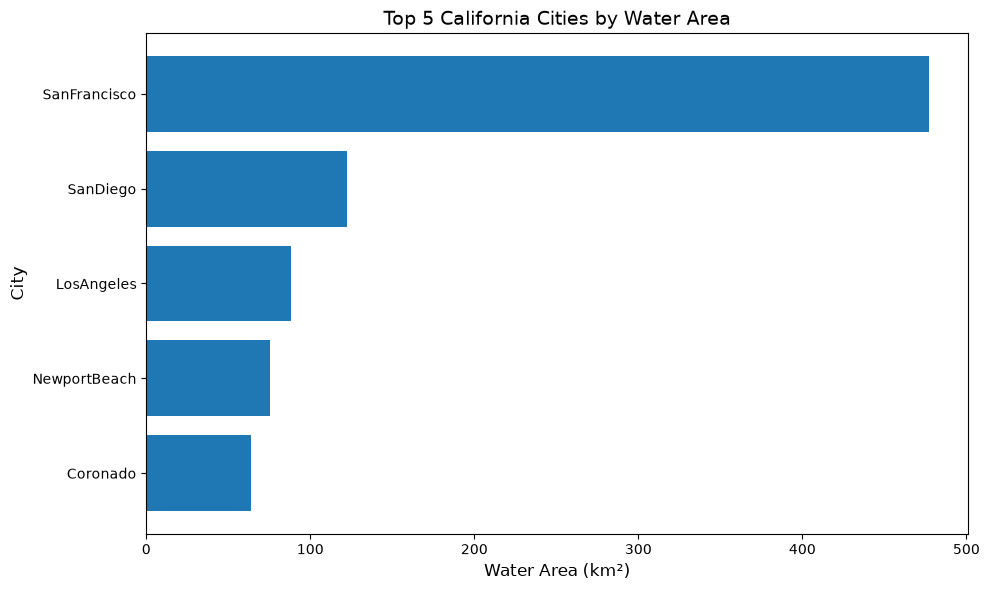

In [107]:
import matplotlib.pyplot as plt

top_5_water = (
    validation.dropna(subset=["area_water_km2"])
    .nlargest(5, "area_water_km2")
    .sort_values("area_water_km2", ascending=True)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_5_water["city"],
    top_5_water["area_water_km2"]
)
plt.title("Top 5 California Cities by Water Area", fontsize=14)
plt.xlabel("Water Area (km²)", fontsize=12)
plt.ylabel("City", fontsize=12)

plt.tight_layout()
plt.show()